# Imports

##### standard python libraries

In [1]:
import pandas as pd
from sqlalchemy import create_engine

In [2]:
from pysdl import SDLClient

In [3]:
import warnings
warnings.filterwarnings('ignore')

##### Custom Libraries

In [4]:
import psql_utilities as psql_utl
import pygmt_utilities as plot_utl

### Set Paths

In [5]:
### path to configuration file of database
path_conf_file = './../../config/database.ini'
### path where to temporary store the file downloaded from SDL
path_tmp_download = '../../sample_data/download_tmp'

### Connect to SDL

In [6]:
client = SDLClient()
client.auth.login()

{'response': 200, 'message': 'Authenticated on SDL successfully.'}


{'message': 'User already attached as andrea.distefano@ingv.it.'}

### Database Connection

In [7]:
db_config = psql_utl.load_config(path_conf_file)
### connect to the database - sqlalchemy
engine = create_engine(db_config['db_uri'])

## What-if Analysis: show flow depth for hypothetical scenarios 

In this notebook we perform a simple what-if analysis, namely given hipotetical scenarios we show the flow depth coming out from the corresponding numerical simulation.

Users can select a scenario by specifing the range of values of the following parameters:
  - *magnitude*: magnitude of the event
  - *Event Location*: 3D bounding box containing the epicenter of the BS-type fault or the baricenter of the mesh faults for PS-event 
  - *dip*: the fault dip angle 
  - *rake*: the fault rake angle of the BS fault or the average rake angle of the mesh of PS-fault
  - *strike*: the fault strike direction
  - *slip*: the fault slip of BS-fault or the average slip of the mesh of the PS fault
  - *fault Lenght*: lenght of the BS-fault
  - *fault Width*: width of the BS-fault
  - *Manning Coefficient*: water-bottom friction used in the simulations

The one can visualize the flow depth for all scenarios that match the specified conditons on the above parameters. 
In addition, users can also select the *Area of Interest*, i.e. Catania or Siracusa, where to visualize the results.

The main query used for this analysis is stored in *'./query_what_if.sql'*, it is a combination of the query described in *3_retrieve_datasets_simulations_parameters* and *2_retrieve_datasets_geospatial*. Namley:

  1. First, we select all simulation runs of the experiment and associate to them the parameters listed above, in our case: Magnitude, Manning Coef, Fault Lenght, Fault Width, mesh_faults, Lon Epicenter, Lat Epicenter, Depth Hypocenter, Strike, Dip, Rake, Slip.

  2. Next, we select simulation runs whose parameter values fall within specified ranges

  3. Then, we retrieve the metadata of the simulation outputs associated with the resulting simulation runs in the specified area of interest.

Finally, we use SDL API to access the corresponding output files. 

In order to compute and plot the flowdepth we use a second query *'./query_bathymetry_grid.sql'* to select the bathymetry files at site of Catania e Siracusa.

### setup

##### read queries from file

In [8]:
query_params = open("./query_what_if.sql", "r")
query_params = query_params.read()

In [9]:
query_bathy_files = open("./query_bathymetry_grid.sql", "r")
query_bathy_files = query_bathy_files.read()

##### set input variables

In [10]:
# magnitude
mag_min = 6
mag_max = 9
# manning coefficient
manning_min = 0.03
manning_max = 0.03
# fault lenght
fault_lenght_min = 80
fault_lenght_max = 200
# fault width
fault_width_min = 30
fault_width_max = 100
# strike
strike_min = 60
strike_max = 70
# dip
dip_min = 50
dip_max = 60
# rake
rake_min = 100
rake_max = 300
# slip
slip_min = 0
slip_max = 10
#
bbox_3d_bs = [15.9,36.,14.6,16.,36.3,15.1]
#bbox_3d_ps = [15.6,37.1,14.6,16.,37.8,20.1]
bbox_3d_ps = [15.3,38.1,42.2,15.5,38.15,42.]
bbox_3d_bsps = [15.6,36,14.6,16.,37.8,20.1]
ev_bbox = bbox_3d_bs
#
bbox_ct = [15.0,37.2,15.15,37.6]
bbox_sr = [15.2,37.0,15.35,37.2]
bbox_all = [0,0,100,100]
area_bbox = bbox_all

### query result

##### define input parameters

In [11]:
dict_params = {'mag_min': mag_min,
               'mag_max': mag_max,
               'manning_min': manning_min,
               'manning_max': manning_max,
               'fault_lenght_min': fault_lenght_min,
               'fault_lenght_max': fault_lenght_max,
               'fault_width_min': fault_width_min,
               'fault_width_max': fault_width_max,
               'strike_min': strike_min,
               'strike_max': strike_max,
               'dip_min': dip_min,
               'dip_max': dip_max,
               'rake_min': rake_min,
               'rake_max': rake_max,
               'slip_min': slip_min,
               'slip_max': slip_max,
               'ev_bbox': ev_bbox,
               'area_bbox': area_bbox
              }

##### run query with pandas

In [12]:
df_ds_params = pd.read_sql(query_params, con=engine,params=dict_params)
df_ds_params = df_ds_params.head(6)
df_ds_params

,ds_path,ds_name,sr_id,sr_path,scen_name,fk_sr_id,seismicity_type,magnitude,manning_coeff,slip_bs_ps,...,fault_centre_lon,fault_centre_lat,fault_centre_depth,fault_lenght,fault_width,strike,dip,mesh_fault_bc_lon,mesh_fault_bc_lat,mesh_fault_bbox
0,CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M8...,C_CT.nc,sr_54426,CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M8...,E01267N3753E01646N3535-BS-M809_E01592N3602_D01...,sr_54426,BS,8.09,0.03,7.525559,...,15.9273,36.0284,14.607,183.454046,38.135,67.5,50.0,None,None,None
1,CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M8...,C_SR.nc,sr_54426,CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M8...,E01267N3753E01646N3535-BS-M809_E01592N3602_D01...,sr_54426,BS,8.09,0.03,7.525559,...,15.9273,36.0284,14.607,183.454046,38.135,67.5,50.0,None,None,None


In [13]:
list_ds_paths = df_ds_params['ds_path'].values.tolist()
list_ds_paths

['CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M809_E01592N3602_D010_S067D50R270_A006995_S075/C_CT.nc',
 'CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M809_E01592N3602_D010_S067D50R270_A006995_S075/C_SR.nc']

**NOTE:** Once we selected the datasets we can use 'ds_path' to identify and access the corresponding file in the experiment folder.

### Plot Flow Depth for Selected Scenario

##### read bathymetry files

In [14]:
df_bathy_files = pd.read_sql(query_bathy_files, con=engine)
df_bathy_files

,site,path_bathy_file
0,C_CT,CT-SR_M100/SIMULATION_SETUP/bati/C_CT.grd
1,C_SR,CT-SR_M100/SIMULATION_SETUP/bati/C_SR.grd


In [15]:
df_bathy_files.set_index('site')['path_bathy_file'].to_dict()

{'C_CT': 'CT-SR_M100/SIMULATION_SETUP/bati/C_CT.grd',
 'C_SR': 'CT-SR_M100/SIMULATION_SETUP/bati/C_SR.grd'}

##### open bathymetry grids for Catania and Siracusa

In [20]:
### API
bathy_grid_sites = plot_utl._get_bathymetry_grids(df_bathy_files=df_bathy_files,path_exp=path_tmp_download,sdl_client=client)
#bathy_grid_sites

File Site: C_CT
Download File CT-SR_M100/SIMULATION_SETUP/bati/C_CT.grd from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__SIMULATION_SETUP__bati__C_CT.grd


{
  "status": "ok",
  "message": "Download CT-SR_M100/SIMULATION_SETUP/bati/C_CT.grd completed successfully!"
}

File Site: C_SR
Download File CT-SR_M100/SIMULATION_SETUP/bati/C_SR.grd from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__SIMULATION_SETUP__bati__C_SR.grd


{
  "status": "ok",
  "message": "Download CT-SR_M100/SIMULATION_SETUP/bati/C_SR.grd completed successfully!"
}

##### show flowdepth

File Site: C_CT
Download File CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M809_E01592N3602_D010_S067D50R270_A006995_S075/C_CT.nc from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__BS_003__E01267N3753E01646N3535-BS-M809_E01592N3602_D010_S067D50R270_A006995_S075__C_CT.nc


{
  "status": "ok",
  "message": "Download CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M809_E01592N3602_D010_S067D50R270_A006995_S075/C_CT.nc completed successfully!"
}

File Site: C_SR
Download File CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M809_E01592N3602_D010_S067D50R270_A006995_S075/C_SR.nc from SDL and save to ../../sample_data/download_tmp/CT-SR_M100__BS_003__E01267N3753E01646N3535-BS-M809_E01592N3602_D010_S067D50R270_A006995_S075__C_SR.nc


{
  "status": "ok",
  "message": "Download CT-SR_M100/BS_003/E01267N3753E01646N3535-BS-M809_E01592N3602_D010_S067D50R270_A006995_S075/C_SR.nc completed successfully!"
}

max depth 11.56 m
max depth 9.88 m


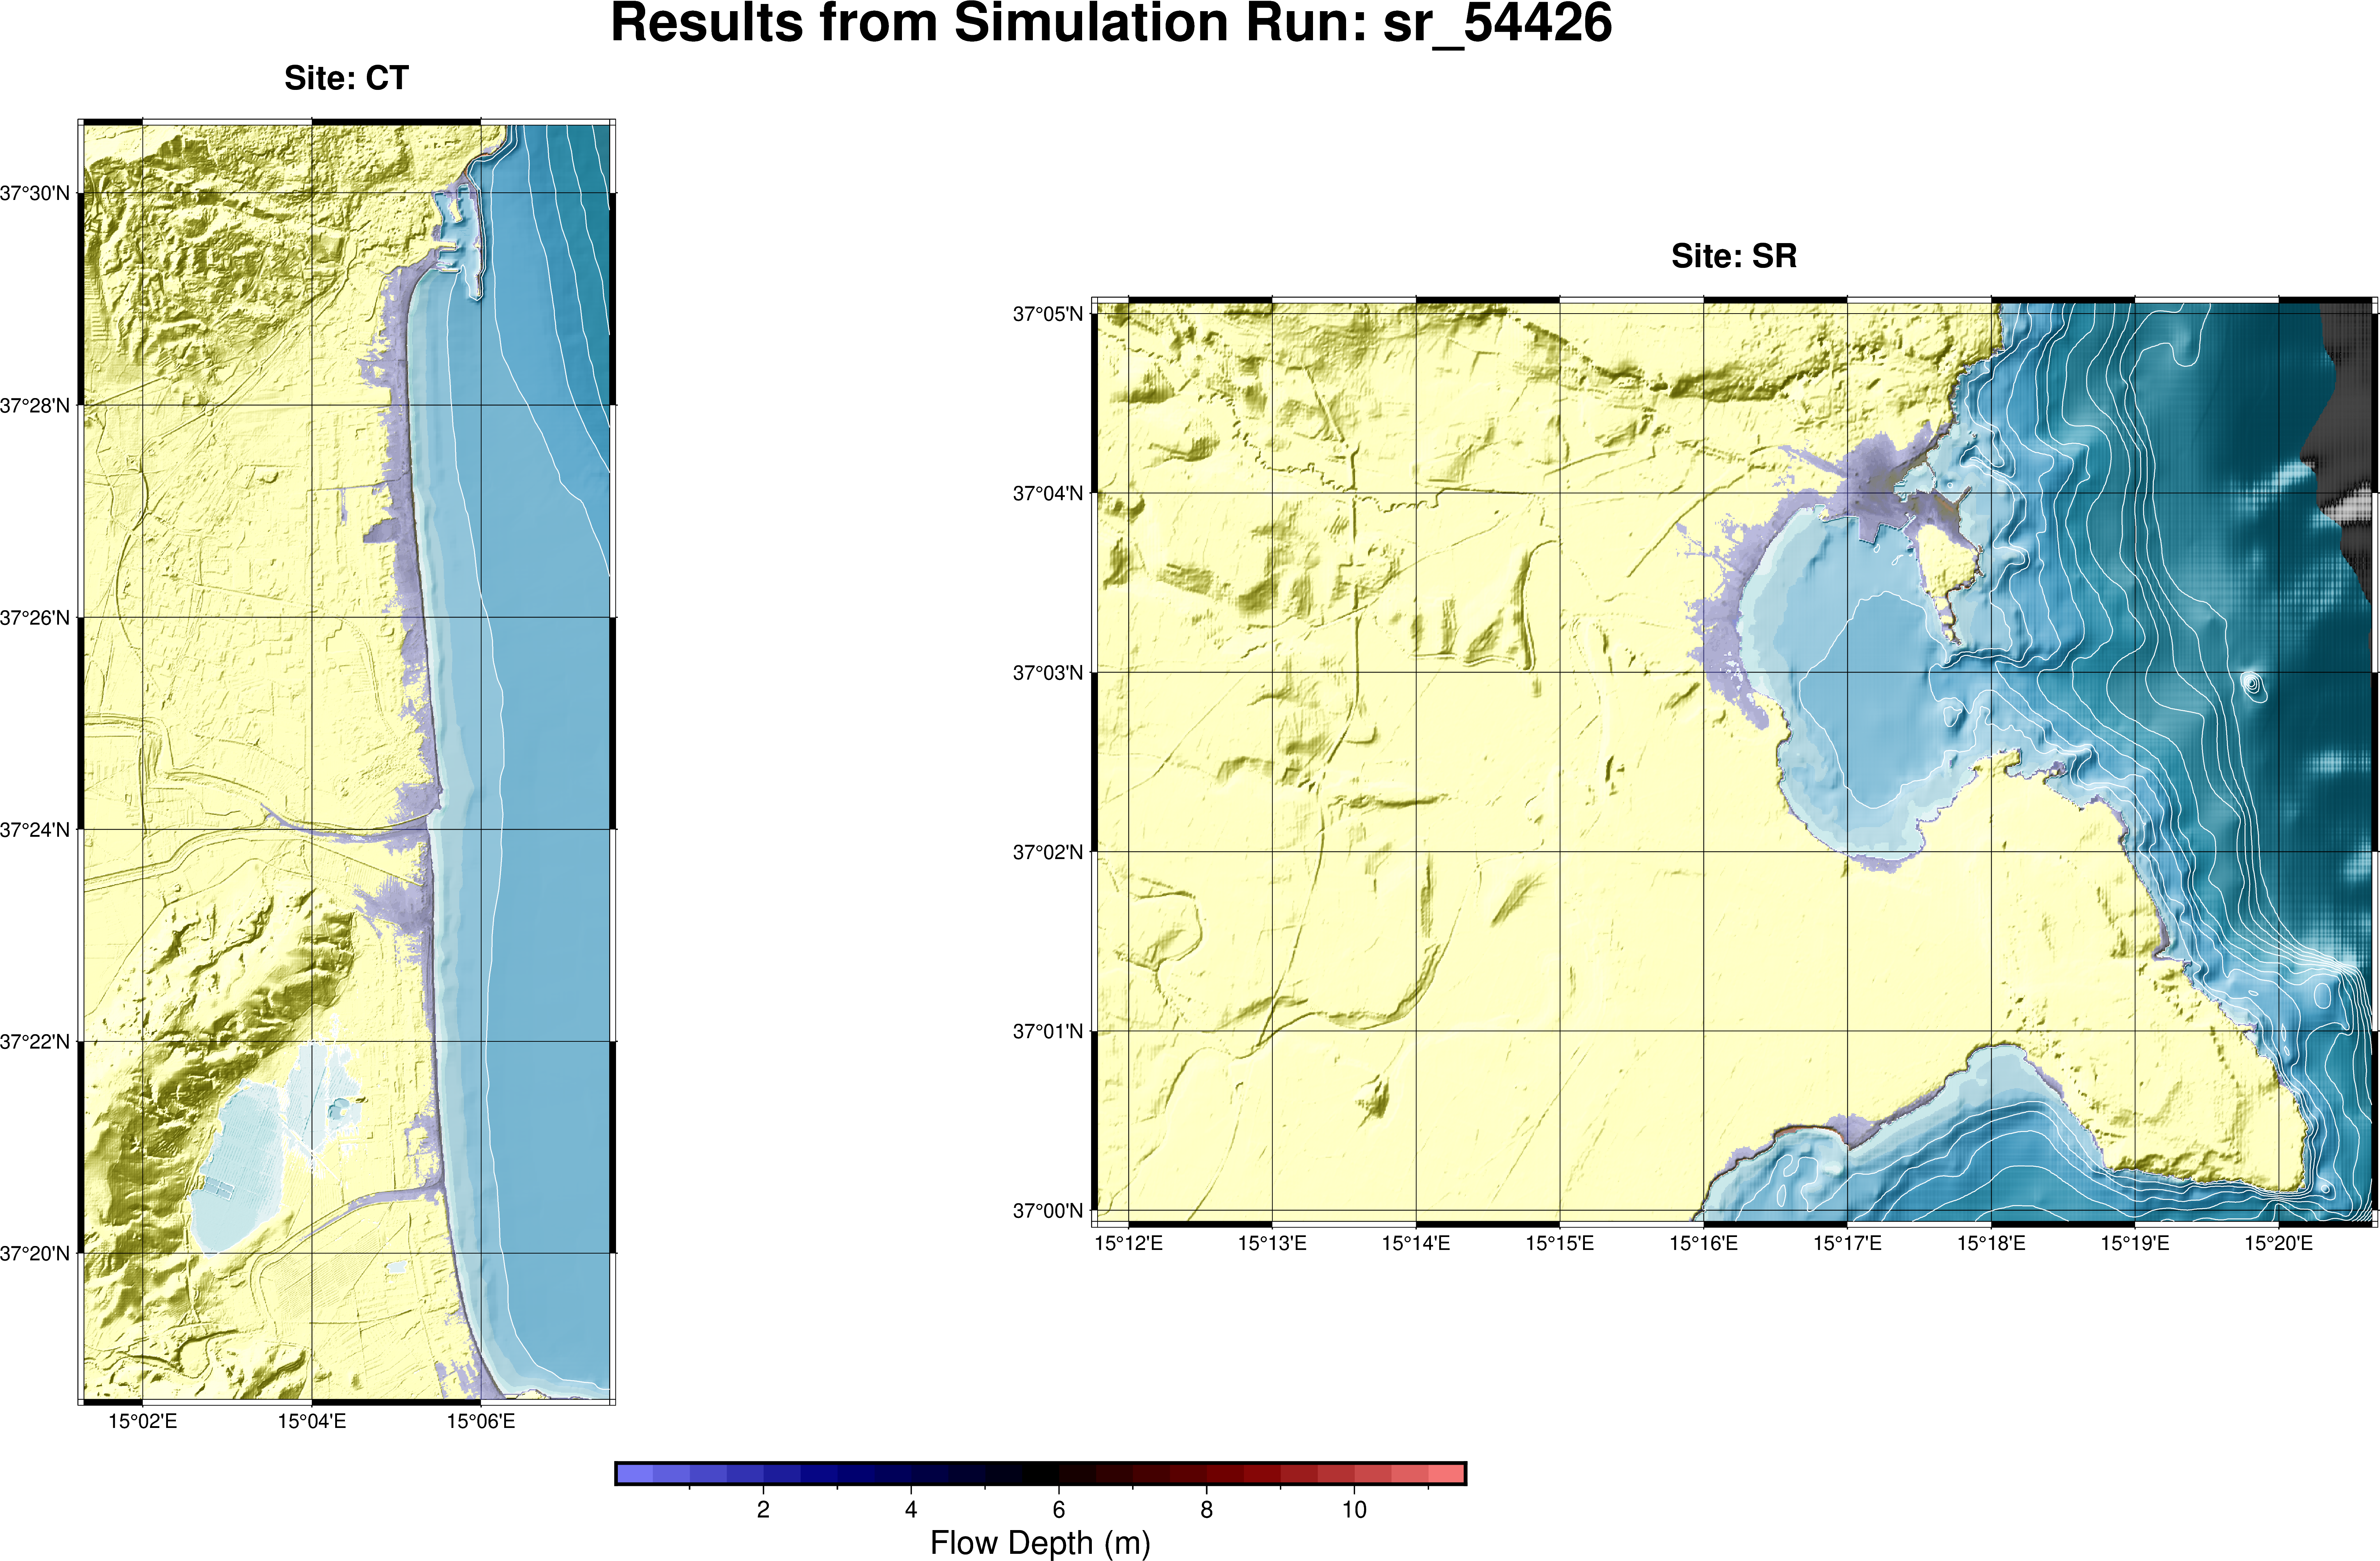

In [19]:
fig = plot_utl.show_map_height(df_ds=df_ds_params,bathy_grid_sites=bathy_grid_sites,path_exp=path_tmp_download,sdl_client=client)
fig.show()

### NOTE (access dataset locally)

If the experiment files have already been downloaded, one can specify the path where the experiment is located (*path_experiment_dataset*) inside the above functions as follows:
   1. open the local bathymtry files:

bathy_grid_sites = plot_utl._get_bathymetry_grids(df_bathy_files=df_bathy_files,path_exp=path_experiment_dataset) 
   
   2. plot flow depth:

fig = plot_utl.show_map_height(df_ds=df_ds_params,bathy_grid_sites=bathy_grid_sites,path_exp=path_experiment_dataset)
